# Part 1 – Semi-supervised labeling of clinical-trial stopping reasons

Goal: label the 1,014 masked trials in `part1_train.csv`, select a model on `part1_val.csv`, predict the 5 reason labels for `part1_test.csv`, and export `reason_labels.csv` for Part 2.

## Loading the data and exploring it

In [17]:
import numpy as np
import pandas as pd

LABELS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]
EMB = [f"emb_{i}" for i in range(150)]

train = pd.read_csv("part1_train.csv")
val = pd.read_csv("part1_val.csv")
test = pd.read_csv("part1_test.csv")
print("shapes:", train.shape, val.shape, test.shape)

shapes: (1171, 166) (78, 166) (312, 161)


In [18]:
# a trial is labeled if none of its 5 reason columns is -100
label_values = train[LABELS]
not_masked = label_values != -100
is_lab = not_masked.all(axis=1)

lab = train[is_lab]
unlab = train[~is_lab]

print("labeled:", len(lab))
print("unlabeled:", len(unlab))

labeled: 157
unlabeled: 1014


In [19]:
# the mean of a 0/1 column is the share of trials with that reason
freq_lab = lab[LABELS].mean()
freq_val = val[LABELS].mean()

freq = pd.DataFrame({"labeled train": freq_lab, "val": freq_val})
print(freq.round(2))

             labeled train   val
Safety                0.10  0.12
Funding               0.05  0.05
Efficacy              0.11  0.18
Recruitment           0.64  0.64
Other                 0.16  0.13


In [20]:
# sum across the 5 columns gives the number of reasons per trial
n_reasons_lab = lab[LABELS].sum(axis=1)
n_reasons_val = val[LABELS].sum(axis=1)

counts_lab = n_reasons_lab.value_counts().sort_index()
counts_val = n_reasons_val.value_counts().sort_index()

print("reasons per trial (labeled):", counts_lab.to_dict())
print("reasons per trial (val):", counts_val.to_dict())

reasons per trial (labeled): {1: 147, 2: 10}
reasons per trial (val): {1: 69, 2: 9}


In [21]:
# the labeled trials should be the oldest and test the newest
sets = {"labeled": lab, "unlabeled": unlab, "val": val, "test": test}

for name, df in sets.items():
    first_year = df["start_year"].min()
    last_year = df["start_year"].max()
    median_year = df["start_year"].median()
    print(f"{name:10s} years {first_year}–{last_year}, median {median_year}")

labeled    years 1993–2010, median 2001.0
unlabeled  years 2003–2010, median 2007.0
val        years 1999–2009, median 2006.0
test       years 2010–2016, median 2011.0


## Preparing the features 

In [22]:
from sklearn.preprocessing import StandardScaler

# the embeddings are really small so I standardize them first
# I fit the scaler on all of train, using the unlabeled embeddings is fine since they have no labels
train_emb = train[EMB]

scaler = StandardScaler()
scaler.fit(train_emb)

print("scaler fitted on", scaler.n_samples_seen_, "trials")

scaler fitted on 1171.0 trials


In [23]:
# take the embedding columns of each set
lab_emb = lab[EMB]
unlab_emb = unlab[EMB]
val_emb = val[EMB]
test_emb = test[EMB]

# apply the same scaling to all of them
X_lab = scaler.transform(lab_emb)
X_unlab = scaler.transform(unlab_emb)
X_val = scaler.transform(val_emb)
X_test = scaler.transform(test_emb)

print("X_lab:", X_lab.shape)
print("X_unlab:", X_unlab.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_lab: (157, 150)
X_unlab: (1014, 150)
X_val: (78, 150)
X_test: (312, 150)


In [24]:
# labels as 0/1 matrices, one column per reason
lab_labels = lab[LABELS]
val_labels = val[LABELS]

Y_lab = lab_labels.values.astype(int)
Y_val = val_labels.values.astype(int)

print("Y_lab:", Y_lab.shape)
print("Y_val:", Y_val.shape)

Y_lab: (157, 5)
Y_val: (78, 5)


In [39]:
# all train embeddings together, labeled first and then unlabeled
X_train_full = np.vstack([X_lab, X_unlab])

print("X_train_full:", X_train_full.shape)

X_train_full: (1171, 150)


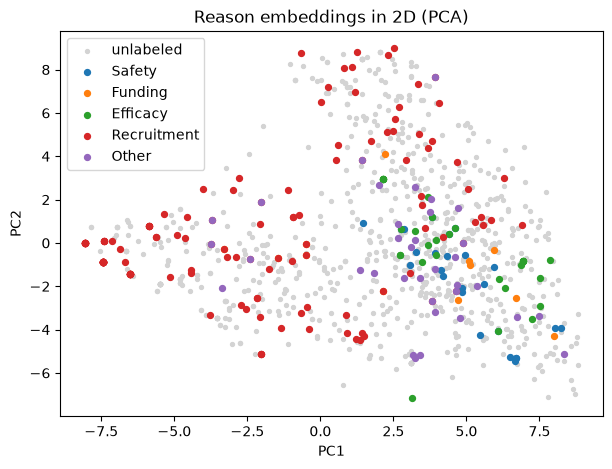

In [25]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# squeeze the 150 dims into 2 just to look at them
pca2 = PCA(n_components=2, random_state=0)
pca2.fit(X_train_full)

# the trials we know the reasons of (labeled train + val)
X_seen = np.vstack([X_lab, X_val])
Y_seen = np.vstack([Y_lab, Y_val])

Z_unlab = pca2.transform(X_unlab)
Z_seen = pca2.transform(X_seen)

plt.figure(figsize=(7, 5))
plt.scatter(Z_unlab[:, 0], Z_unlab[:, 1], c="lightgrey", s=8, label="unlabeled")
for i, name in enumerate(LABELS):
    has_reason = Y_seen[:, i] == 1
    plt.scatter(Z_seen[has_reason, 0], Z_seen[has_reason, 1], s=18, label=name)
plt.legend()
plt.title("Reason embeddings in 2D (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [26]:
# how much variance we keep with fewer dimensions
pca_full = PCA()
pca_full.fit(X_train_full)

var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

for k in [2, 10, 20, 50, 100]:
    print(f"{k:3d} PCs keep {cum_var[k-1]:.2f} of the variance")

  2 PCs keep 0.24 of the variance
 10 PCs keep 0.55 of the variance
 20 PCs keep 0.69 of the variance
 50 PCs keep 0.86 of the variance
100 PCs keep 0.96 of the variance


## Training a baseline on the labeled trials

In [27]:
from sklearn.metrics import f1_score

# function I'll use every time to score a model on val
def evaluate(Y_true, Y_pred, name):
    sample_f1 = f1_score(Y_true, Y_pred, average="samples", zero_division=0)
    macro_f1 = f1_score(Y_true, Y_pred, average="macro", zero_division=0)
    per_label = f1_score(Y_true, Y_pred, average=None, zero_division=0)

    row = {"model": name, "sample F1": sample_f1, "macro F1": macro_f1}
    for label, score in zip(LABELS, per_label):
        row[label] = score
    return row

In [32]:
# probs above the threshold become 1, the rest 0
def to_labels(probs, threshold=0.5):
    above = probs >= threshold
    preds = above.astype(int)

    # every trial has at least one reason so if none is above the threshold I take the highest one
    n_reasons = preds.sum(axis=1)
    no_label = n_reasons == 0

    best_reason = probs.argmax(axis=1)
    rows_to_fix = np.where(no_label)[0]
    cols_to_fix = best_reason[no_label]
    preds[rows_to_fix, cols_to_fix] = 1

    return preds

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# first model, only using the 157 trials that already have labels
# OneVsRest fits a separate logistic regression for each of the 5 reasons
base_lr = LogisticRegression(max_iter=1000)
baseline = OneVsRestClassifier(base_lr)
baseline.fit(X_lab, Y_lab)

print("trained on", X_lab.shape[0], "trials")

trained on 157 trials


In [34]:
# predict on val and score it
val_probs = baseline.predict_proba(X_val)
val_preds = to_labels(val_probs)

results = []
baseline_row = evaluate(Y_val, val_preds, "baseline LR (labeled only)")
results.append(baseline_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR (labeled only),0.85,0.68,0.941,0.4,0.667,0.971,0.421


In [36]:
# trying different C values, lower C means stronger regularization
# with only 157 labeled trials I want to see how much this changes the scores

C_values = [0.01, 0.1, 1, 10]

for C in C_values:
    lr = LogisticRegression(C=C, max_iter=1000)
    model = OneVsRestClassifier(lr)
    model.fit(X_lab, Y_lab)

    probs = model.predict_proba(X_val)
    preds = to_labels(probs)
    row = evaluate(Y_val, preds, f"baseline LR C={C}")

    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]
    funding_f1 = row["Funding"]
    print(f"C={C:<5} sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f} | Funding F1 {funding_f1:.3f}")

C=0.01  sample F1 0.795 | macro F1 0.522 | Funding F1 0.000
C=0.1   sample F1 0.842 | macro F1 0.667 | Funding F1 0.400
C=1     sample F1 0.850 | macro F1 0.680 | Funding F1 0.400
C=10    sample F1 0.868 | macro F1 0.719 | Funding F1 0.400


In [37]:
# C=10 was the best one so I keep it as the baseline
best_C = 10
baseline_lr = LogisticRegression(C=best_C, max_iter=1000)
baseline = OneVsRestClassifier(baseline_lr)
baseline.fit(X_lab, Y_lab)

val_probs = baseline.predict_proba(X_val)
val_preds = to_labels(val_probs)

results = []
baseline_row = evaluate(Y_val, val_preds, "baseline LR C=10 (labeled only)")
results.append(baseline_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.4,0.72,0.961,0.571


## Labeling the unlabeled trials with clustering

In [40]:
# clustering in 150 dims with only ~1200 trials doesn't work well so I reduce to 20 first
# from the variance check above, 20 PCs keep around 70% of the info
n_dims = 20

pca = PCA(n_components=n_dims, random_state=0)
pca.fit(X_train_full)

print("PCA fitted with", n_dims, "components")

PCA fitted with 20 components


In [41]:
# project every set into the same 20 dims
Z_lab = pca.transform(X_lab)
Z_unlab = pca.transform(X_unlab)
Z_val = pca.transform(X_val)
Z_test = pca.transform(X_test)

# labeled + unlabeled together, this is what k-means will cluster
Z_train_full = np.vstack([Z_lab, Z_unlab])

print("Z_train_full:", Z_train_full.shape)
print("Z_val:", Z_val.shape)
print("Z_test:", Z_test.shape)

Z_train_full: (1171, 20)
Z_val: (78, 20)
Z_test: (312, 20)


In [42]:
from sklearn.cluster import KMeans

# k-means on all train trials, labeled and unlabeled together
k = 10
kmeans = KMeans(n_clusters=k, n_init=10, random_state=0)
kmeans.fit(Z_train_full)

cluster_sizes = np.bincount(kmeans.labels_, minlength=k)
print("trials per cluster:", cluster_sizes)

trials per cluster: [138 109 153 110 143  56  86 194 154  28]


In [43]:
# which cluster each labeled trial ended up in
cl_lab = kmeans.predict(Z_lab)

lab_df = pd.DataFrame(Y_lab, columns=LABELS)
lab_df["cluster"] = cl_lab

# share of each reason among the labeled trials of every cluster
reason_share = lab_df.groupby("cluster")[LABELS].mean()
all_clusters = range(k)
profile = reason_share.reindex(all_clusters)

# how many labeled trials each cluster has (0 if none)
lab_counts = lab_df["cluster"].value_counts()
n_lab_per_cluster = lab_counts.reindex(all_clusters, fill_value=0)

profile["n labeled"] = n_lab_per_cluster
profile["n total"] = cluster_sizes

profile.round(2)

,Safety,Funding,Efficacy,Recruitment,Other,n labeled,n total
cluster,,,,,,,
0,0.50,0.00,0.00,0.00,0.50,20,138
1,0.00,0.00,0.00,1.00,0.00,25,109
2,0.35,0.18,0.18,0.06,0.29,17,153
3,0.00,0.10,0.00,0.90,0.10,10,110
4,0.00,0.00,0.00,0.91,0.09,11,143
5,0.00,0.00,0.93,0.07,0.00,15,56
6,0.00,0.00,0.00,0.80,0.20,5,86
7,0.00,0.10,0.00,0.97,0.08,39,194
8,0.00,0.00,0.00,1.00,0.15,13,154


In [45]:
# a cluster gets a reason if at least half of its labeled trials have it
cluster_share = profile[LABELS].values
cluster_labels = to_labels(cluster_share)

cluster_label_df = pd.DataFrame(cluster_labels, columns=LABELS)
cluster_label_df

,Safety,Funding,Efficacy,Recruitment,Other
0,1,0,0,0,1
1,0,0,0,1,0
2,1,0,0,0,0
3,0,0,0,1,0
4,0,0,0,1,0
5,0,0,1,0,0
6,0,0,0,1,0
7,0,0,0,1,0
8,0,0,0,1,0
9,0,0,0,0,1


In [46]:
# each unlabeled trial takes the labels of the cluster it ended up in
cl_unlab = kmeans.predict(Z_unlab)
Y_unlab_km = cluster_labels[cl_unlab]

pseudo_counts = Y_unlab_km.sum(axis=0)
print("pseudo-labels per reason:", dict(zip(LABELS, pseudo_counts)))

pseudo-labels per reason: {'Safety': np.int64(254), 'Funding': np.int64(0), 'Efficacy': np.int64(41), 'Recruitment': np.int64(693), 'Other': np.int64(144)}


In [47]:
# same idea on val, to see how good the cluster labels are
cl_val = kmeans.predict(Z_val)
val_preds_km = cluster_labels[cl_val]

km_row = evaluate(Y_val, val_preds_km, "k-means labels directly (k=10)")
results.append(km_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.4,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.0,0.444,0.970,0.381


## Labeling the unlabeled trials with label spreading

In [48]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

from sklearn.semi_supervised import LabelSpreading

# LabelSpreading can only handle one label at a time so I do it separately for each reason
# the trials without a label need to be -1
# I start with Safety which is the first column just to see how the input looks before doing all five reasons
safety_col = 0
y_lab_one = Y_lab[:, safety_col]
y_unlab_one = np.full(len(Z_unlab), -1)
y_spread = np.concatenate([y_lab_one, y_unlab_one])

print("labeled with Safety:", (y_spread == 1).sum())
print("labeled without Safety:", (y_spread == 0).sum())
print("unlabeled:", (y_spread == -1).sum())

labeled with Safety: 16
labeled without Safety: 141
unlabeled: 1014


In [49]:
# label spreading for one reason only
# it gives back the probability of that reason for the unlabeled trials and for val
def spread_one_reason(col, n_neighbors):
    # the labels I know for this reason and -1 for all the unlabeled trials
    y_lab_col = Y_lab[:, col]
    y_unlab_col = np.full(len(Z_unlab), -1)
    y_col = np.concatenate([y_lab_col, y_unlab_col])

    # each trial passes its label to its closest neighbors
    ls = LabelSpreading(kernel="knn", n_neighbors=n_neighbors, alpha=0.2, max_iter=100)
    ls.fit(Z_train_full, y_col)

    # the second column is the probability that the trial has this reason
    train_probs = ls.label_distributions_[:, 1]
    train_probs = np.nan_to_num(train_probs)

    # the labeled trials come first so I skip them and keep only the unlabeled ones
    n_lab = len(Z_lab)
    unlab_probs_col = train_probs[n_lab:]

    # same probability for the val trials
    val_probs_col = ls.predict_proba(Z_val)[:, 1]
    val_probs_col = np.nan_to_num(val_probs_col)

    return unlab_probs_col, val_probs_col

In [50]:
# I try it on Safety first to check that it works
safety_unlab_probs, safety_val_probs = spread_one_reason(safety_col, n_neighbors=10)

print("unlabeled probs:", safety_unlab_probs.shape)
print("val probs:", safety_val_probs.shape)
print("unlabeled trials with Safety prob above 0.5:", (safety_unlab_probs >= 0.5).sum())

unlabeled probs: (1014,)
val probs: (78,)
unlabeled trials with Safety prob above 0.5: 97


/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


In [51]:
# now the same thing for all five reasons and I put the columns next to each other
def spread_labels(n_neighbors):
    unlab_cols = []
    val_cols = []

    for col in range(len(LABELS)):
        unlab_probs_col, val_probs_col = spread_one_reason(col, n_neighbors)
        unlab_cols.append(unlab_probs_col)
        val_cols.append(val_probs_col)

    unlab_probs = np.column_stack(unlab_cols)
    val_probs = np.column_stack(val_cols)
    return unlab_probs, val_probs

In [52]:
# first try with 10 neighbors for every reason
unlab_probs_ls, val_probs_ls = spread_labels(n_neighbors=10)

# the unlabeled trials get a reason when its probability is high enough
Y_unlab_ls = to_labels(unlab_probs_ls)
pseudo_counts_ls = Y_unlab_ls.sum(axis=0)

print("pseudo-labels per reason:", dict(zip(LABELS, pseudo_counts_ls)))

pseudo-labels per reason: {'Safety': np.int64(338), 'Funding': np.int64(16), 'Efficacy': np.int64(89), 'Recruitment': np.int64(453), 'Other': np.int64(163)}


/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


In [53]:
# how good label spreading is on val when I use it directly
val_preds_ls = to_labels(val_probs_ls)
ls_row = evaluate(Y_val, val_preds_ls, "label spreading directly with 10 neighbors")
results.append(ls_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.4,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.0,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.0,0.720,0.800,0.333


In [54]:
# I think some trials get probability 0 for every reason
# when that happens argmax picks the first column which is Safety
unlab_row_sums = unlab_probs_ls.sum(axis=1)
val_row_sums = val_probs_ls.sum(axis=1)

unlab_all_zero = (unlab_row_sums == 0).sum()
val_all_zero = (val_row_sums == 0).sum()

print("unlabeled trials with all zeros:", unlab_all_zero)
print("val trials with all zeros:", val_all_zero)

unlabeled trials with all zeros: 238
val trials with all zeros: 14


In [55]:
# more neighbors should connect more trials to the labeled ones
neighbor_values = [10, 20, 30, 50]

for n_nb in neighbor_values:
    unlab_probs_try, val_probs_try = spread_labels(n_neighbors=n_nb)

    n_zero_unlab = (unlab_probs_try.sum(axis=1) == 0).sum()

    val_preds_try = to_labels(val_probs_try)
    row = evaluate(Y_val, val_preds_try, "try")
    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]

    Y_unlab_try = to_labels(unlab_probs_try)
    n_funding = Y_unlab_try[:, 1].sum()

    print(f"neighbors={n_nb:<3} all-zero unlabeled {n_zero_unlab:<4} | sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f} | Funding pseudo-labels {n_funding}")

/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


neighbors=10  all-zero unlabeled 238  | sample F1 0.628 | macro F1 0.443 | Funding pseudo-labels 16
neighbors=20  all-zero unlabeled 149  | sample F1 0.705 | macro F1 0.464 | Funding pseudo-labels 17
neighbors=30  all-zero unlabeled 125  | sample F1 0.744 | macro F1 0.485 | Funding pseudo-labels 16
neighbors=50  all-zero unlabeled 125  | sample F1 0.744 | macro F1 0.485 | Funding pseudo-labels 6


/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


In [56]:
# the all-zero count stops at 125 even with 50 neighbors
# so I check if many trials have the exact same embedding
Z_rounded = np.round(Z_train_full, 6)
unique_rows, group_sizes = np.unique(Z_rounded, axis=0, return_counts=True)
biggest_groups = np.sort(group_sizes)[::-1][:5]

print("different embeddings in train:", len(unique_rows), "out of", len(Z_train_full))
print("biggest groups of identical embeddings:", biggest_groups)

different embeddings in train: 859 out of 1171
biggest groups of identical embeddings: [72 48 21 16 14]


In [57]:
# now the same thing for all five reasons and I put the columns next to each other
def spread_labels(n_neighbors):
    unlab_cols = []
    val_cols = []

    for col in range(len(LABELS)):
        unlab_probs_col, val_probs_col = spread_one_reason(col, n_neighbors)
        unlab_cols.append(unlab_probs_col)
        val_cols.append(val_probs_col)

    unlab_probs = np.column_stack(unlab_cols)
    val_probs = np.column_stack(val_cols)

    # trials that no label can reach get the share of each reason in the labeled data
    # so they end up with Recruitment which is the most common reason instead of Safety
    reason_share_lab = Y_lab.mean(axis=0)
    unlab_zero = unlab_probs.sum(axis=1) == 0
    val_zero = val_probs.sum(axis=1) == 0
    unlab_probs[unlab_zero] = reason_share_lab
    val_probs[val_zero] = reason_share_lab

    return unlab_probs, val_probs

In [58]:
# same loop as before but now trials that no label can reach get Recruitment
for n_nb in neighbor_values:
    unlab_probs_try, val_probs_try = spread_labels(n_neighbors=n_nb)

    val_preds_try = to_labels(val_probs_try)
    row = evaluate(Y_val, val_preds_try, "try")
    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]

    Y_unlab_try = to_labels(unlab_probs_try)
    counts_try = Y_unlab_try.sum(axis=0).tolist()

    print(f"neighbors={n_nb:<3} sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f} | pseudo-labels {dict(zip(LABELS, counts_try))}")

neighbors=10  sample F1 0.808 | macro F1 0.531 | pseudo-labels {'Safety': 100, 'Funding': 16, 'Efficacy': 89, 'Recruitment': 691, 'Other': 163}
neighbors=20  sample F1 0.833 | macro F1 0.534 | pseudo-labels {'Safety': 103, 'Funding': 17, 'Efficacy': 95, 'Recruitment': 698, 'Other': 133}
neighbors=30  sample F1 0.833 | macro F1 0.536 | pseudo-labels {'Safety': 108, 'Funding': 16, 'Efficacy': 90, 'Recruitment': 708, 'Other': 125}
neighbors=50  sample F1 0.833 | macro F1 0.536 | pseudo-labels {'Safety': 101, 'Funding': 6, 'Efficacy': 99, 'Recruitment': 710, 'Other': 118}


/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


In [59]:
# 30 neighbors gave the best macro F1 and still keeps 16 Funding labels so I keep that one
best_nb = 30
unlab_probs_ls, val_probs_ls = spread_labels(n_neighbors=best_nb)

Y_unlab_ls = to_labels(unlab_probs_ls)
val_preds_ls = to_labels(val_probs_ls)

ls_row = evaluate(Y_val, val_preds_ls, "label spreading directly with 30 neighbors")
results.append(ls_row)

pd.DataFrame(results).round(3)

/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/Users/davidebacchini/Library/Python/3.14/lib/python/site-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.4,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.0,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.0,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.0,0.667,0.980,0.333


## Training the final classifiers on the augmented data

In [60]:
# trains the same logistic regression as the baseline on the labeled trials plus the pseudo-labeled ones
def train_lr_on_augmented(Y_unlab_pseudo, C=best_C):
    X_aug = np.vstack([X_lab, X_unlab])
    Y_aug = np.vstack([Y_lab, Y_unlab_pseudo])

    lr = LogisticRegression(C=C, max_iter=1000)
    model = OneVsRestClassifier(lr)
    model.fit(X_aug, Y_aug)
    return model

In [61]:
# logistic regression with the k-means pseudo-labels
lr_km = train_lr_on_augmented(Y_unlab_km)

val_probs_lr_km = lr_km.predict_proba(X_val)
val_preds_lr_km = to_labels(val_probs_lr_km)

lr_km_row = evaluate(Y_val, val_preds_lr_km, "LR on labeled and k-means pseudo-labels")
results.append(lr_km_row)

In [62]:
# logistic regression with the label spreading pseudo-labels
lr_ls = train_lr_on_augmented(Y_unlab_ls)

val_probs_lr_ls = lr_ls.predict_proba(X_val)
val_preds_lr_ls = to_labels(val_probs_lr_ls)

lr_ls_row = evaluate(Y_val, val_preds_lr_ls, "LR on labeled and label spreading pseudo-labels")
results.append(lr_ls_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632


In [64]:
# puts the labeled and the pseudo-labeled trials together
# the real labels count as 1 and the pseudo-labels count less because they can be wrong
def build_weighted_data(Y_unlab_pseudo, pseudo_weight):
    X_aug = np.vstack([X_lab, X_unlab])
    Y_aug = np.vstack([Y_lab, Y_unlab_pseudo])

    n_lab = len(X_lab)
    n_unlab = len(X_unlab)
    w_lab = np.ones(n_lab)
    w_unlab = np.full(n_unlab, pseudo_weight)
    weights = np.concatenate([w_lab, w_unlab])

    return X_aug, Y_aug, weights

In [65]:
# small check with weight 0.1 on the label spreading pseudo-labels
X_check, Y_check, w_check = build_weighted_data(Y_unlab_ls, pseudo_weight=0.1)

print("X:", X_check.shape)
print("Y:", Y_check.shape)
print("weight of the first trial:", w_check[0])
print("weight of the last trial:", w_check[-1])

X: (1171, 150)
Y: (1171, 5)
weight of the first trial: 1.0
weight of the last trial: 0.1


In [66]:
# OneVsRest has no way to give each trial its own weight
# so I train one logistic regression for every reason myself
def train_weighted_lr(Y_unlab_pseudo, pseudo_weight, C=best_C):
    X_aug, Y_aug, weights = build_weighted_data(Y_unlab_pseudo, pseudo_weight)

    models = []
    for col in range(len(LABELS)):
        y_reason = Y_aug[:, col]

        lr = LogisticRegression(C=C, max_iter=1000)
        lr.fit(X_aug, y_reason, sample_weight=weights)
        models.append(lr)

    return models

In [67]:
# probability of each reason from the 5 models put next to each other
def predict_weighted_lr(models, X):
    prob_cols = []
    for lr in models:
        prob_reason = lr.predict_proba(X)[:, 1]
        prob_cols.append(prob_reason)

    probs = np.column_stack(prob_cols)
    return probs

In [68]:
# the pseudo-labels are noisy so I try giving them less weight than the real labels
weight_values = [0.05, 0.1, 0.2, 0.5, 1.0]
pseudo_sets = {"k-means": Y_unlab_km, "label spreading": Y_unlab_ls}

for method, Y_pseudo in pseudo_sets.items():
    for w in weight_values:
        models = train_weighted_lr(Y_pseudo, pseudo_weight=w)
        probs = predict_weighted_lr(models, X_val)
        preds = to_labels(probs)
        row = evaluate(Y_val, preds, "try")

        sample_f1 = row["sample F1"]
        macro_f1 = row["macro F1"]
        funding_f1 = row["Funding"]
        print(f"{method:<16} weight={w:<5} sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f} | Funding F1 {funding_f1:.3f}")

k-means          weight=0.05  sample F1 0.793 | macro F1 0.586 | Funding F1 0.400
k-means          weight=0.1   sample F1 0.778 | macro F1 0.491 | Funding F1 0.000
k-means          weight=0.2   sample F1 0.761 | macro F1 0.542 | Funding F1 0.400
k-means          weight=0.5   sample F1 0.767 | macro F1 0.560 | Funding F1 0.400
k-means          weight=1.0   sample F1 0.767 | macro F1 0.563 | Funding F1 0.400
label spreading  weight=0.05  sample F1 0.823 | macro F1 0.631 | Funding F1 0.400
label spreading  weight=0.1   sample F1 0.818 | macro F1 0.617 | Funding F1 0.400
label spreading  weight=0.2   sample F1 0.810 | macro F1 0.605 | Funding F1 0.400
label spreading  weight=0.5   sample F1 0.797 | macro F1 0.636 | Funding F1 0.667
label spreading  weight=1.0   sample F1 0.797 | macro F1 0.638 | Funding F1 0.667


In [70]:
# a reason is sure when its probability is close to 1 or close to 0
# I keep only the unlabeled trials where all five reasons are sure
def confident_mask(unlab_probs, min_conf):
    sure_yes = unlab_probs >= min_conf
    sure_no = unlab_probs <= 1 - min_conf
    sure_each_reason = sure_yes | sure_no
    sure_all_reasons = sure_each_reason.all(axis=1)
    return sure_all_reasons

In [71]:
# how many unlabeled trials are left for each confidence level and which reasons they have
for min_conf in [0.7, 0.8, 0.9]:
    mask = confident_mask(unlab_probs_ls, min_conf)
    n_kept = mask.sum()
    kept_counts = Y_unlab_ls[mask].sum(axis=0).tolist()
    print(f"min_conf={min_conf} kept {n_kept} trials | {dict(zip(LABELS, kept_counts))}")

min_conf=0.7 kept 670 trials | {'Safety': 73, 'Funding': 5, 'Efficacy': 67, 'Recruitment': 473, 'Other': 61}
min_conf=0.8 kept 582 trials | {'Safety': 57, 'Funding': 1, 'Efficacy': 59, 'Recruitment': 421, 'Other': 45}
min_conf=0.9 kept 492 trials | {'Safety': 42, 'Funding': 0, 'Efficacy': 38, 'Recruitment': 382, 'Other': 30}


In [72]:
# same as train_weighted_lr but the pseudo-labeled trials that are not sure get weight 0
# so the model just ignores them
def train_lr_confident(Y_unlab_pseudo, keep_mask, pseudo_weight, C=best_C):
    X_aug = np.vstack([X_lab, X_unlab])
    Y_aug = np.vstack([Y_lab, Y_unlab_pseudo])

    w_lab = np.ones(len(X_lab))
    w_unlab = np.where(keep_mask, pseudo_weight, 0.0)
    weights = np.concatenate([w_lab, w_unlab])

    models = []
    for col in range(len(LABELS)):
        y_reason = Y_aug[:, col]

        lr = LogisticRegression(C=C, max_iter=1000)
        lr.fit(X_aug, y_reason, sample_weight=weights)
        models.append(lr)

    return models

In [73]:
# only the confident label spreading pseudo-labels with a few different weights
for min_conf in [0.7, 0.8, 0.9]:
    mask = confident_mask(unlab_probs_ls, min_conf)

    for w in [0.2, 0.5, 1.0]:
        models = train_lr_confident(Y_unlab_ls, mask, pseudo_weight=w)
        probs = predict_weighted_lr(models, X_val)
        preds = to_labels(probs)
        row = evaluate(Y_val, preds, "try")

        sample_f1 = row["sample F1"]
        macro_f1 = row["macro F1"]
        print(f"min_conf={min_conf} weight={w:<4} kept {mask.sum():<4} | sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f}")

min_conf=0.7 weight=0.2  kept 670  | sample F1 0.861 | macro F1 0.669
min_conf=0.7 weight=0.5  kept 670  | sample F1 0.825 | macro F1 0.615
min_conf=0.7 weight=1.0  kept 670  | sample F1 0.821 | macro F1 0.605
min_conf=0.8 weight=0.2  kept 582  | sample F1 0.863 | macro F1 0.676
min_conf=0.8 weight=0.5  kept 582  | sample F1 0.859 | macro F1 0.668
min_conf=0.8 weight=1.0  kept 582  | sample F1 0.855 | macro F1 0.659
min_conf=0.9 weight=0.2  kept 492  | sample F1 0.863 | macro F1 0.687
min_conf=0.9 weight=0.5  kept 492  | sample F1 0.863 | macro F1 0.687
min_conf=0.9 weight=1.0  kept 492  | sample F1 0.863 | macro F1 0.687


In [74]:
# k-means worked best with weight 0.05 so that version goes in the results table
models_km_w = train_weighted_lr(Y_unlab_km, pseudo_weight=0.05)
val_probs_km_w = predict_weighted_lr(models_km_w, X_val)
val_preds_km_w = to_labels(val_probs_km_w)

km_w_row = evaluate(Y_val, val_preds_km_w, "LR with k-means pseudo-labels weight 0.05")
results.append(km_w_row)

In [75]:
# label spreading worked best keeping only the trials with confidence above 0.9
mask_09 = confident_mask(unlab_probs_ls, 0.9)
models_ls_conf = train_lr_confident(Y_unlab_ls, mask_09, pseudo_weight=1.0)
val_probs_ls_conf = predict_weighted_lr(models_ls_conf, X_val)
val_preds_ls_conf = to_labels(val_probs_ls_conf)

ls_conf_row = evaluate(Y_val, val_preds_ls_conf, "LR with confident label spreading pseudo-labels 0.9")
results.append(ls_conf_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632
6,LR with k-means pseudo-labels weight 0.05,0.793,0.586,0.581,0.400,0.600,0.970,0.381
7,LR with confident label spreading pseudo-label...,0.863,0.687,0.900,0.400,0.720,0.970,0.444


In [76]:
from sklearn.neighbors import KNeighborsClassifier

# KNN can predict all five reasons at once
# predict_proba gives back one array per reason so I take the column for has this reason
def knn_probs(X_train, Y_train, X_eval, n_neighbors, metric):
    knn = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric, weights="distance")
    knn.fit(X_train, Y_train)

    probs_per_reason = knn.predict_proba(X_eval)
    prob_cols = []
    for p in probs_per_reason:
        prob_has_reason = p[:, 1]
        prob_cols.append(prob_has_reason)

    probs = np.column_stack(prob_cols)
    return probs

In [77]:
# KNN trained only on the 157 labeled trials
k_values = [3, 5, 10, 15]

for metric in ["euclidean", "cosine"]:
    for k_nn in k_values:
        probs = knn_probs(X_lab, Y_lab, X_val, k_nn, metric)
        preds = to_labels(probs)
        row = evaluate(Y_val, preds, "try")

        sample_f1 = row["sample F1"]
        macro_f1 = row["macro F1"]
        print(f"labeled only  {metric:<9} k={k_nn:<3} sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f}")

labeled only  euclidean k=3   sample F1 0.863 | macro F1 0.613
labeled only  euclidean k=5   sample F1 0.833 | macro F1 0.532
labeled only  euclidean k=10  sample F1 0.846 | macro F1 0.570
labeled only  euclidean k=15  sample F1 0.833 | macro F1 0.563
labeled only  cosine    k=3   sample F1 0.846 | macro F1 0.606
labeled only  cosine    k=5   sample F1 0.868 | macro F1 0.614
labeled only  cosine    k=10  sample F1 0.846 | macro F1 0.594
labeled only  cosine    k=15  sample F1 0.833 | macro F1 0.577


In [78]:
# KNN trained on the labeled trials plus the 492 confident label spreading trials
X_conf = np.vstack([X_lab, X_unlab[mask_09]])
Y_conf = np.vstack([Y_lab, Y_unlab_ls[mask_09]])
print("training trials:", X_conf.shape[0])

for metric in ["euclidean", "cosine"]:
    for k_nn in k_values:
        probs = knn_probs(X_conf, Y_conf, X_val, k_nn, metric)
        preds = to_labels(probs)
        row = evaluate(Y_val, preds, "try")

        sample_f1 = row["sample F1"]
        macro_f1 = row["macro F1"]
        print(f"with pseudo   {metric:<9} k={k_nn:<3} sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f}")

training trials: 649
with pseudo   euclidean k=3   sample F1 0.872 | macro F1 0.631
with pseudo   euclidean k=5   sample F1 0.846 | macro F1 0.576
with pseudo   euclidean k=10  sample F1 0.821 | macro F1 0.539
with pseudo   euclidean k=15  sample F1 0.795 | macro F1 0.471
with pseudo   cosine    k=3   sample F1 0.876 | macro F1 0.625
with pseudo   cosine    k=5   sample F1 0.863 | macro F1 0.623
with pseudo   cosine    k=10  sample F1 0.838 | macro F1 0.564
with pseudo   cosine    k=15  sample F1 0.825 | macro F1 0.523


In [79]:
# labeled only KNN worked best with cosine and k=5
val_probs_knn = knn_probs(X_lab, Y_lab, X_val, 5, "cosine")
val_preds_knn = to_labels(val_probs_knn)

knn_row = evaluate(Y_val, val_preds_knn, "KNN cosine k=5 labeled only")
results.append(knn_row)

# with the confident pseudo-labels it worked best with cosine and k=3
val_probs_knn_conf = knn_probs(X_conf, Y_conf, X_val, 3, "cosine")
val_preds_knn_conf = to_labels(val_probs_knn_conf)

knn_conf_row = evaluate(Y_val, val_preds_knn_conf, "KNN cosine k=3 with confident label spreading pseudo-labels")
results.append(knn_conf_row)

In [80]:
# LR is better on the rare reasons and KNN on the common ones
# so I average their probabilities to see if together they do better
probs_lr_part = val_probs_ls_conf
probs_knn_part = val_probs_knn_conf
ens_probs = (probs_lr_part + probs_knn_part) / 2

ens_preds = to_labels(ens_probs)
ens_row = evaluate(Y_val, ens_preds, "average of LR and KNN with confident pseudo-labels")
results.append(ens_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632
6,LR with k-means pseudo-labels weight 0.05,0.793,0.586,0.581,0.400,0.600,0.970,0.381
7,LR with confident label spreading pseudo-label...,0.863,0.687,0.900,0.400,0.720,0.970,0.444
8,KNN cosine k=5 labeled only,0.868,0.614,0.750,0.000,0.815,0.980,0.526
9,KNN cosine k=3 with confident label spreading ...,0.876,0.625,0.800,0.000,0.720,0.980,0.625


## Testing which features help

In [ ]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# Morgan fingerprints of the drugs, this is the code from the project pdf
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def trial_fingerprint(smiles_field):
    if pd.isna(smiles_field):
        return np.zeros(1024)

    fps = []
    for s in smiles_field.split(";"):
        mol = Chem.MolFromSmiles(s)
        if mol is not None:
            fps.append(gen.GetFingerprintAsNumPy(mol))

    if len(fps) == 0:
        return np.zeros(1024)
    return np.max(fps, axis=0)

In [85]:
# one fingerprint per trial for the labeled and val trials
fp_lab_list = lab["drug_smiles"].apply(trial_fingerprint)
fp_val_list = val["drug_smiles"].apply(trial_fingerprint)

# turn the lists into matrices with one row per trial
fp_lab = np.vstack(fp_lab_list)
fp_val = np.vstack(fp_val_list)

print("fp_lab:", fp_lab.shape)
print("fp_val:", fp_val.shape)

fp_lab: (157, 1024)
fp_val: (78, 1024)


In [86]:
# I scale the start year with the mean and std of train like the embeddings
year_mean = train["start_year"].mean()
year_std = train["start_year"].std()

year_lab_scaled = (lab["start_year"] - year_mean) / year_std
year_val_scaled = (val["start_year"] - year_mean) / year_std

# one column so I can stack it next to the embeddings
year_lab = year_lab_scaled.values.reshape(-1, 1)
year_val = year_val_scaled.values.reshape(-1, 1)

print("year_lab:", year_lab.shape)
print("year_val:", year_val.shape)

year_lab: (157, 1)
year_val: (78, 1)


In [87]:
# a lot of trials have no matched drug so their fingerprint is all zeros
has_drug_lab = lab["drug_smiles"].notna()
share_with_drug = has_drug_lab.mean()

print("labeled trials with a matched drug:", round(share_with_drug, 2))

labeled trials with a matched drug: 0.62


In [88]:
# the different combinations of features I want to compare
emb_year_lab = np.hstack([X_lab, year_lab])
emb_year_val = np.hstack([X_val, year_val])

emb_fp_lab = np.hstack([X_lab, fp_lab])
emb_fp_val = np.hstack([X_val, fp_val])

all_lab = np.hstack([X_lab, year_lab, fp_lab])
all_val = np.hstack([X_val, year_val, fp_val])

feature_sets = {
    "embeddings only": (X_lab, X_val),
    "drug fingerprints only": (fp_lab, fp_val),
    "embeddings + start year": (emb_year_lab, emb_year_val),
    "embeddings + drug fingerprints": (emb_fp_lab, emb_fp_val),
    "everything": (all_lab, all_val),
}

In [89]:
# same baseline LR every time and only the features change
for name, (X_train_f, X_val_f) in feature_sets.items():
    lr = LogisticRegression(C=best_C, max_iter=2000)
    model = OneVsRestClassifier(lr)
    model.fit(X_train_f, Y_lab)

    probs = model.predict_proba(X_val_f)
    preds = to_labels(probs)
    row = evaluate(Y_val, preds, name)

    n_features = X_train_f.shape[1]
    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]
    print(f"{name:<32} n features {n_features:<5} | sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f}")

embeddings only                  n features 150   | sample F1 0.868 | macro F1 0.719
drug fingerprints only           n features 1024  | sample F1 0.585 | macro F1 0.238
embeddings + start year          n features 151   | sample F1 0.876 | macro F1 0.738
embeddings + drug fingerprints   n features 1174  | sample F1 0.842 | macro F1 0.608
everything                       n features 1175  | sample F1 0.842 | macro F1 0.605


In [90]:
# start year for the unlabeled and test trials scaled the same way as before
year_unlab_scaled = (unlab["start_year"] - year_mean) / year_std
year_test_scaled = (test["start_year"] - year_mean) / year_std

year_unlab = year_unlab_scaled.values.reshape(-1, 1)
year_test = year_test_scaled.values.reshape(-1, 1)

# embeddings with the start year next to them
X_unlab_year = np.hstack([X_unlab, year_unlab])
X_test_year = np.hstack([X_test, year_test])

print("X_unlab_year:", X_unlab_year.shape)
print("X_test_year:", X_test_year.shape)

X_unlab_year: (1014, 151)
X_test_year: (312, 151)


In [91]:
# same as train_lr_confident but I can choose which features to use
# if keep_mask is all False it is just the LR on the labeled trials
def train_lr_features(X_lab_f, X_unlab_f, Y_unlab_pseudo, keep_mask, C=best_C):
    X_aug = np.vstack([X_lab_f, X_unlab_f])
    Y_aug = np.vstack([Y_lab, Y_unlab_pseudo])

    w_lab = np.ones(len(X_lab_f))
    w_unlab = np.where(keep_mask, 1.0, 0.0)
    weights = np.concatenate([w_lab, w_unlab])

    models = []
    for col in range(len(LABELS)):
        y_reason = Y_aug[:, col]

        lr = LogisticRegression(C=C, max_iter=2000)
        lr.fit(X_aug, y_reason, sample_weight=weights)
        models.append(lr)

    return models

In [92]:
# LR with embeddings and start year trained only on the labeled trials
no_pseudo = np.zeros(len(X_unlab), dtype=bool)
models_year = train_lr_features(emb_year_lab, X_unlab_year, Y_unlab_ls, no_pseudo)

val_probs_year = predict_weighted_lr(models_year, emb_year_val)
val_preds_year = to_labels(val_probs_year)
year_row = evaluate(Y_val, val_preds_year, "LR embeddings + start year labeled only")
results.append(year_row)

# same features but also with the confident label spreading pseudo-labels
models_year_conf = train_lr_features(emb_year_lab, X_unlab_year, Y_unlab_ls, mask_09)

val_probs_year_conf = predict_weighted_lr(models_year_conf, emb_year_val)
val_preds_year_conf = to_labels(val_probs_year_conf)
year_conf_row = evaluate(Y_val, val_preds_year_conf, "LR embeddings + start year with confident pseudo-labels")
results.append(year_conf_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632
6,LR with k-means pseudo-labels weight 0.05,0.793,0.586,0.581,0.400,0.600,0.970,0.381
7,LR with confident label spreading pseudo-label...,0.863,0.687,0.900,0.400,0.720,0.970,0.444
8,KNN cosine k=5 labeled only,0.868,0.614,0.750,0.000,0.815,0.980,0.526
9,KNN cosine k=3 with confident label spreading ...,0.876,0.625,0.800,0.000,0.720,0.980,0.625


In [93]:
# self-training: the best LR gives the labels to the unlabeled trials itself
# then I train it again adding only the trials it was really sure about
unlab_probs_self = predict_weighted_lr(models_year, X_unlab_year)
Y_unlab_self = to_labels(unlab_probs_self)

for min_conf in [0.8, 0.9, 0.95]:
    mask_self = confident_mask(unlab_probs_self, min_conf)
    models_self = train_lr_features(emb_year_lab, X_unlab_year, Y_unlab_self, mask_self)

    val_probs_self = predict_weighted_lr(models_self, emb_year_val)
    val_preds_self = to_labels(val_probs_self)
    row = evaluate(Y_val, val_preds_self, "try")

    n_kept = mask_self.sum()
    kept_counts = Y_unlab_self[mask_self].sum(axis=0).tolist()
    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]
    print(f"min_conf={min_conf} kept {n_kept:<4} | sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f} | {dict(zip(LABELS, kept_counts))}")

min_conf=0.8 kept 828  | sample F1 0.902 | macro F1 0.810 | {'Safety': 59, 'Funding': 8, 'Efficacy': 66, 'Recruitment': 622, 'Other': 105}
min_conf=0.9 kept 721  | sample F1 0.872 | macro F1 0.705 | {'Safety': 47, 'Funding': 5, 'Efficacy': 42, 'Recruitment': 569, 'Other': 76}
min_conf=0.95 kept 643  | sample F1 0.872 | macro F1 0.705 | {'Safety': 34, 'Funding': 5, 'Efficacy': 31, 'Recruitment': 530, 'Other': 56}


In [94]:
# I check the values around 0.8 to see if it is a real improvement or just luck on the small val set
for min_conf in [0.6, 0.7, 0.75, 0.8, 0.85]:
    mask_self = confident_mask(unlab_probs_self, min_conf)
    models_self = train_lr_features(emb_year_lab, X_unlab_year, Y_unlab_self, mask_self)

    val_probs_self = predict_weighted_lr(models_self, emb_year_val)
    val_preds_self = to_labels(val_probs_self)
    row = evaluate(Y_val, val_preds_self, "try")

    n_kept = mask_self.sum()
    sample_f1 = row["sample F1"]
    macro_f1 = row["macro F1"]
    print(f"min_conf={min_conf:<5} kept {n_kept:<4} | sample F1 {sample_f1:.3f} | macro F1 {macro_f1:.3f}")

min_conf=0.6   kept 939  | sample F1 0.885 | macro F1 0.737
min_conf=0.7   kept 878  | sample F1 0.897 | macro F1 0.800
min_conf=0.75  kept 853  | sample F1 0.897 | macro F1 0.799
min_conf=0.8   kept 828  | sample F1 0.902 | macro F1 0.810
min_conf=0.85  kept 780  | sample F1 0.885 | macro F1 0.737


In [95]:
# self-training with min_conf 0.8 goes in the results table
mask_self_08 = confident_mask(unlab_probs_self, 0.8)
models_self_08 = train_lr_features(emb_year_lab, X_unlab_year, Y_unlab_self, mask_self_08)

val_probs_self_08 = predict_weighted_lr(models_self_08, emb_year_val)
val_preds_self_08 = to_labels(val_probs_self_08)

self_row = evaluate(Y_val, val_preds_self_08, "self-training LR embeddings + start year min_conf 0.8")
results.append(self_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632
6,LR with k-means pseudo-labels weight 0.05,0.793,0.586,0.581,0.400,0.600,0.970,0.381
7,LR with confident label spreading pseudo-label...,0.863,0.687,0.900,0.400,0.720,0.970,0.444
8,KNN cosine k=5 labeled only,0.868,0.614,0.750,0.000,0.815,0.980,0.526
9,KNN cosine k=3 with confident label spreading ...,0.876,0.625,0.800,0.000,0.720,0.980,0.625


## Tuning the thresholds for the label shift

In [96]:
# for each reason I try different thresholds on val and keep the one with the best F1
# if nothing beats 0.5 I keep 0.5
threshold_values = np.round(np.arange(0.2, 0.75, 0.05), 2)
best_thresholds = []

for col, name in enumerate(LABELS):
    probs_reason = val_probs_self_08[:, col]
    y_reason = Y_val[:, col]

    scores = []
    for t in threshold_values:
        preds_reason = (probs_reason >= t).astype(int)
        scores.append(f1_score(y_reason, preds_reason, zero_division=0))

    preds_05 = (probs_reason >= 0.5).astype(int)
    score_05 = f1_score(y_reason, preds_05, zero_division=0)
    best_score = max(scores)

    if best_score > score_05:
        best_t = threshold_values[np.argmax(scores)]
    else:
        best_t = 0.5
    best_thresholds.append(best_t)

    print(f"{name:<12} F1 at 0.5 {score_05:.3f} | best threshold {best_t:.2f} | best F1 {best_score:.3f}")

Safety       F1 at 0.5 0.941 | best threshold 0.50 | best F1 0.941
Funding      F1 at 0.5 0.667 | best threshold 0.50 | best F1 0.667
Efficacy     F1 at 0.5 0.800 | best threshold 0.50 | best F1 0.800
Recruitment  F1 at 0.5 0.961 | best threshold 0.55 | best F1 0.980
Other        F1 at 0.5 0.636 | best threshold 0.50 | best F1 0.636


In [97]:
# to_labels also works with one threshold per reason
best_thresholds = np.array(best_thresholds)
val_preds_tuned = to_labels(val_probs_self_08, threshold=best_thresholds)

tuned_row = evaluate(Y_val, val_preds_tuned, "self-training with tuned thresholds")
results.append(tuned_row)

pd.DataFrame(results).round(3)

,model,sample F1,macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,baseline LR C=10 (labeled only),0.868,0.719,0.941,0.400,0.720,0.961,0.571
1,k-means labels directly (k=10),0.744,0.444,0.424,0.000,0.444,0.970,0.381
2,label spreading directly with 10 neighbors,0.628,0.443,0.364,0.000,0.720,0.800,0.333
3,label spreading directly with 30 neighbors,0.833,0.536,0.700,0.000,0.667,0.980,0.333
4,LR on labeled and k-means pseudo-labels,0.767,0.563,0.485,0.400,0.600,0.950,0.381
5,LR on labeled and label spreading pseudo-labels,0.797,0.638,0.600,0.667,0.348,0.942,0.632
6,LR with k-means pseudo-labels weight 0.05,0.793,0.586,0.581,0.400,0.600,0.970,0.381
7,LR with confident label spreading pseudo-label...,0.863,0.687,0.900,0.400,0.720,0.970,0.444
8,KNN cosine k=5 labeled only,0.868,0.614,0.750,0.000,0.815,0.980,0.526
9,KNN cosine k=3 with confident label spreading ...,0.876,0.625,0.800,0.000,0.720,0.980,0.625


## Making the final predictions

In [98]:
# trains one logistic regression per reason on whatever data I give it
def train_lr_on(X_train_f, Y_train_f, C=best_C):
    models = []
    for col in range(len(LABELS)):
        y_reason = Y_train_f[:, col]

        lr = LogisticRegression(C=C, max_iter=2000)
        lr.fit(X_train_f, y_reason)
        models.append(lr)

    return models

In [99]:
# val has all the labels so for the final model I add it to the labeled trials
X_real = np.vstack([emb_year_lab, emb_year_val])
Y_real = np.vstack([Y_lab, Y_val])

base_models = train_lr_on(X_real, Y_real)
print("trained on", X_real.shape[0], "trials with real labels")

trained on 235 trials with real labels


In [100]:
# the first model labels the unlabeled trials and I keep the ones it is sure about
unlab_probs_final = predict_weighted_lr(base_models, X_unlab_year)
Y_unlab_final = to_labels(unlab_probs_final)
mask_final = confident_mask(unlab_probs_final, 0.8)

# then I train again with the real labels plus the confident pseudo-labels
X_final = np.vstack([X_real, X_unlab_year[mask_final]])
Y_final = np.vstack([Y_real, Y_unlab_final[mask_final]])
final_models = train_lr_on(X_final, Y_final)

print("confident pseudo-labeled trials kept:", mask_final.sum())
print("final training trials:", X_final.shape[0])

confident pseudo-labeled trials kept: 833
final training trials: 1068


In [101]:
# predictions on the test trials
test_probs = predict_weighted_lr(final_models, X_test_year)
test_preds = to_labels(test_probs)

# share of each reason in the test predictions compared with the real labels in train and val
share_test = test_preds.mean(axis=0)
share_real = Y_real.mean(axis=0)
share_df = pd.DataFrame({"real labels": share_real, "test predictions": share_test}, index=LABELS)
print(share_df.round(2))

             real labels  test predictions
Safety              0.11              0.15
Funding             0.05              0.02
Efficacy            0.13              0.13
Recruitment         0.64              0.58
Other               0.15              0.26


In [102]:
# format of the Kaggle submission
sample_sub = pd.read_csv("part1_sample_submission.csv")
print(sample_sub.head())

        ID    Predicted
0  TR00756  Recruitment
1  TR05267  Recruitment
2  TR10354  Recruitment
3  TR01930  Recruitment
4  TR01046  Recruitment


In [103]:
# Kaggle wants the names of the predicted reasons separated by a space
def preds_to_text(row_preds):
    names = []
    for col, name in enumerate(LABELS):
        if row_preds[col] == 1:
            names.append(name)
    return " ".join(names)

test_text = [preds_to_text(row) for row in test_preds]
print(test_text[:5])

['Efficacy', 'Safety', 'Safety', 'Recruitment', 'Other']


In [104]:
# one row per test trial with the ID and the predicted reasons
submission = pd.DataFrame({"ID": test["ID"].values, "Predicted": test_text})
submission.to_csv("part1_submission.csv", index=False)

same_ids = set(submission["ID"]) == set(sample_sub["ID"])
print(submission.head())
print("rows:", len(submission))
print("same IDs as the sample submission:", same_ids)

        ID    Predicted
0  TR00756     Efficacy
1  TR05267       Safety
2  TR10354       Safety
3  TR01930  Recruitment
4  TR01046        Other
rows: 312
same IDs as the sample submission: True


In [105]:
# labels for the unlabeled train trials from the final model
unlab_probs_last = predict_weighted_lr(final_models, X_unlab_year)
unlab_preds_last = to_labels(unlab_probs_last)
print("unlabeled trials:", unlab_preds_last.shape)

unlabeled trials: (1014, 5)


In [106]:
# one small table for each group of trials
def make_part(ids, Y, source, split):
    part = pd.DataFrame(Y, columns=LABELS)
    part.insert(0, "ID", ids)
    part["source"] = source
    part["split"] = split
    return part

lab_part = make_part(lab["ID"].values, Y_lab, "true", "train labeled")
val_part = make_part(val["ID"].values, Y_val, "true", "val")
unlab_part = make_part(unlab["ID"].values, unlab_preds_last, "predicted", "train unlabeled")
test_part = make_part(test["ID"].values, test_preds, "predicted", "test")

In [107]:
# all 1561 Part 1 trials in one file for Pri
reason_labels = pd.concat([lab_part, val_part, unlab_part, test_part], ignore_index=True)
reason_labels.to_csv("reason_labels.csv", index=False)

print("rows:", len(reason_labels))
print(reason_labels["source"].value_counts())
print(reason_labels.head())

rows: 1561
source
predicted    1326
true          235
Name: count, dtype: int64
        ID  Safety  Funding  Efficacy  Recruitment  Other source  \
0  TR04011       0        0         0            1      0   true   
1  TR09312       0        0         0            1      0   true   
2  TR01012       0        0         0            1      0   true   
3  TR08630       0        0         0            1      1   true   
4  TR09705       0        0         1            0      0   true   

           split  
0  train labeled  
1  train labeled  
2  train labeled  
3  train labeled  
4  train labeled  
